# 01 - Preprocessing

Before running the particle filters, we build the observed data $(y_t)$ from the raw S&P 500 prices of each period. The logic lives in `src/sv_pf/preprocess.py`; this notebook only runs it and inspects the output.

**Pipeline** (per period)
1. **Check** the raw data: unique and increasing dates, no NaN, $C_t > 0$, and OHLC consistency ($H_t \ge \max(O_t, C_t)$, $L_t \le \min(O_t, C_t)$). OHLC inconsistencies only raise a warning, since small errors exist in Yahoo data.
2. **Compute** the log-returns in percent, $y_t = 100\,\log(P_t / P_{t-1})$, and drop the first row (NaN).
3. **Save** to `data/processed/`: $y_t$ with the aligned OHLC columns, which are reused later for the range-based volatility proxies (Parkinson, Garman-Klass).

In [26]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from sv_pf.config import DATA_PROCESSED, PERIODS

### Returns Visualization

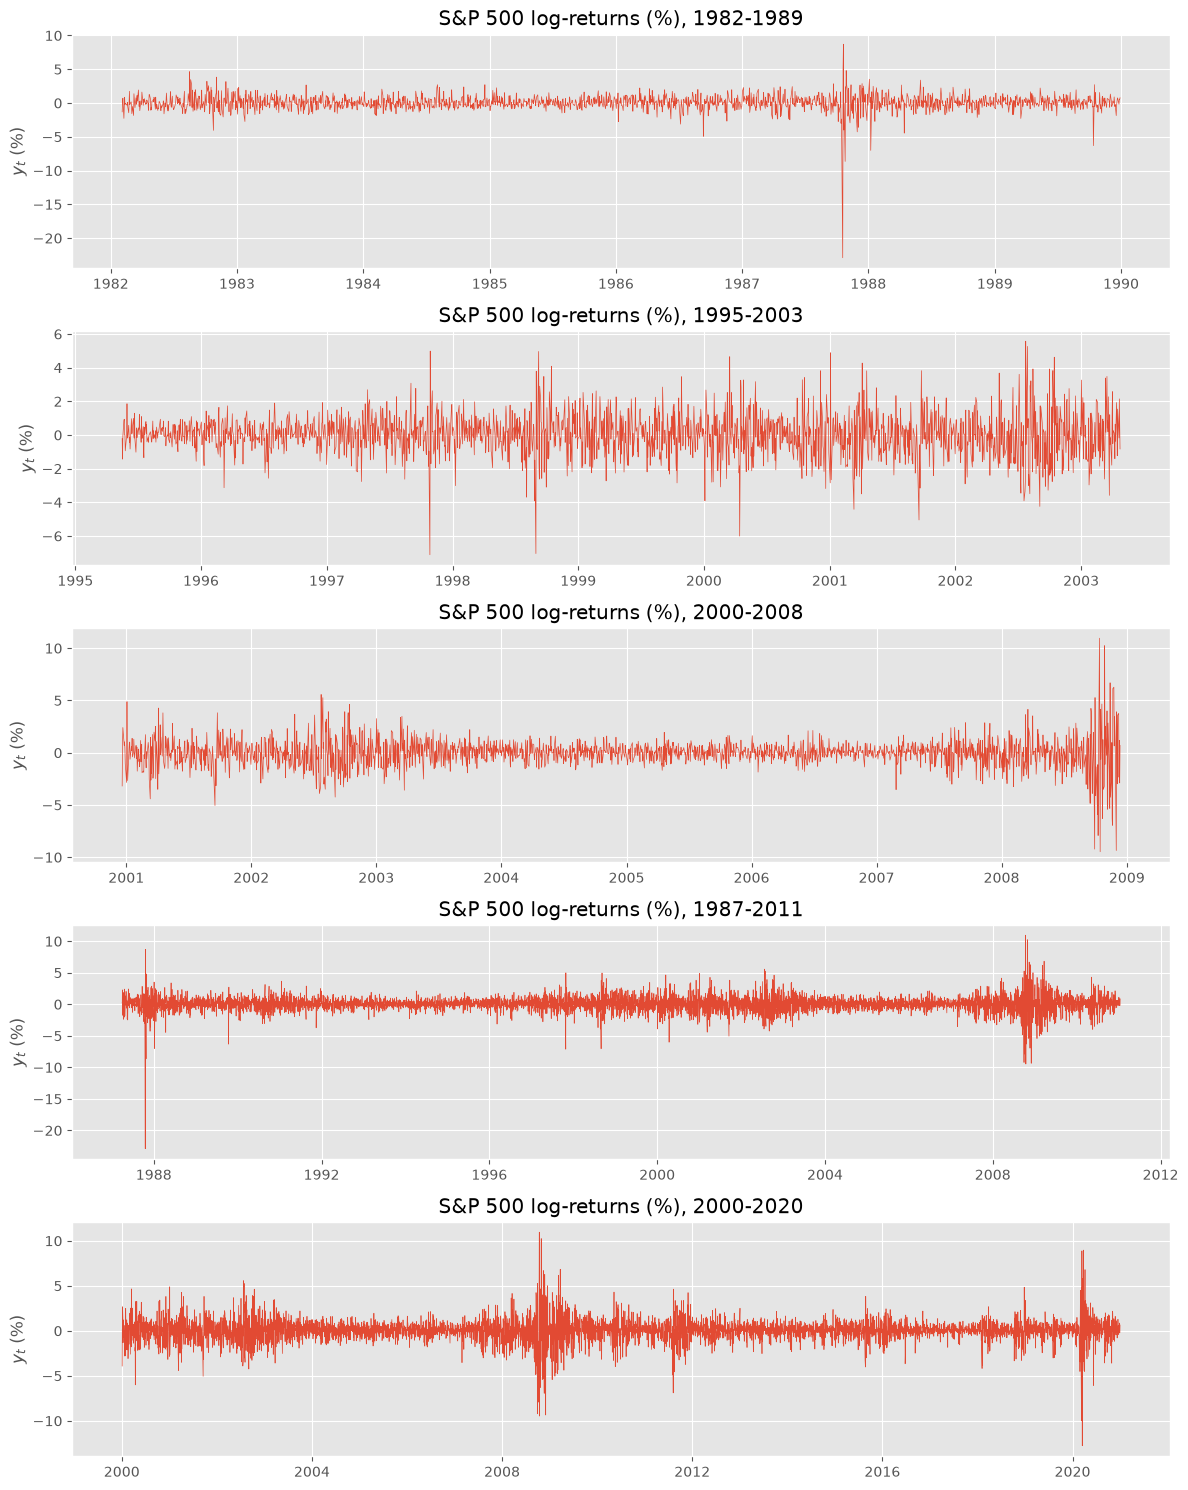

In [27]:
fig, axes = plt.subplots(len(PERIODS), 1, figsize=(12, 3 * len(PERIODS)))

for ax, name in zip(axes, PERIODS):
    df = pd.read_csv(Path(DATA_PROCESSED) / f"returns_{name}.csv", index_col="Date", parse_dates=True)
    ax.plot(df.index, df["y"], lw=0.5)
    ax.set_title(f"S&P 500 log-returns (%), {name}")
    ax.set_ylabel("$y_t$ (%)")

fig.tight_layout()
plt.show()